Baseline Model

In [68]:
import warnings
warnings.filterwarnings('ignore')


In [ ]:
import sys
sys.path.append("..")

import numpy as np
from src.config import PROCESSED_DATA_DIR
from src.data.versioning import load_dataset_version

data = load_dataset_version(PROCESSED_DATA_DIR / "v_ac996888") #version without payer

X_train = data["X_train"]
y_train = data["y_train"]
groups_train = data["groups_train"]

print(X_train.shape, y_train.mean())

(79567, 108) 0.11399198160041223


heatmap

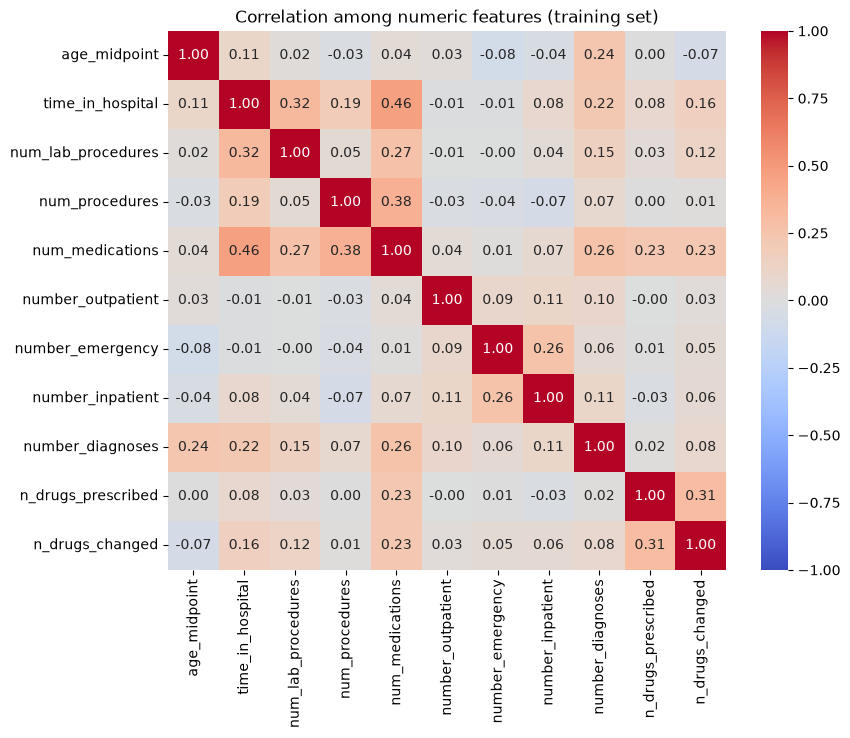

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = X_train[numeric_cols].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation among numeric features (training set)")
plt.show()

most correlated pairs

In [9]:
corr_all = X_train.corr()

upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
pairs = upper.stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)

print(pairs.head(15))
print("\nPairs involving payer columns:")
print(pairs[[("payer_" in a or "payer_" in b) for a, b in pairs.index]].head(8))

gender_Female          gender_Male             -1.000000
rosiglitazone_No       rosiglitazone_Steady    -0.978231
pioglitazone_No        pioglitazone_Steady     -0.973419
metformin_No           metformin_Steady        -0.948453
repaglinide_No         repaglinide_Steady      -0.948137
glimepiride_No         glimepiride_Steady      -0.946825
glipizide_No           glipizide_Steady        -0.938100
glyburide_No           glyburide_Steady        -0.926597
race_AfricanAmerican   race_Caucasian          -0.829945
admission_source_id_1  admission_source_id_7   -0.731763
admission_type_id_1    admission_source_id_7    0.714584
n_drugs_prescribed     change_flag              0.714090
                       diabetes_med_flag        0.698578
n_drugs_changed        change_flag              0.631599
insulin_No             insulin_Steady          -0.618922
dtype: float64

Pairs involving payer columns:
Series([], dtype: float64)


Scores of a model that ignores the patient entirely 

In [10]:
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss

base_rate = y_train.mean()
dummy_pred = np.full(len(y_train), base_rate)

print("AUROC: ", roc_auc_score(y_train, dummy_pred))
print("AUPRC: ", average_precision_score(y_train, dummy_pred))
print("Brier: ", brier_score_loss(y_train, dummy_pred))

AUROC:  0.5
AUPRC:  0.11399198160041223
Brier:  0.1009978097312235


logistic regression

In [11]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Columns with more than 2 distinct values are counts/magnitudes; the rest are 0/1 flags
numeric_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]
print(len(numeric_cols), "columns to scale:", numeric_cols)

preprocess = ColumnTransformer(
    [("scale", StandardScaler(), numeric_cols)],
    remainder="passthrough",
)

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    model, X_train, y_train,
    groups=groups_train,
    cv=cv,
    scoring={"auroc": "roc_auc", "auprc": "average_precision", "brier": "neg_brier_score"},
)

print(f"AUROC: {scores['test_auroc'].mean():.4f} +/- {scores['test_auroc'].std():.4f}")
print(f"AUPRC: {scores['test_auprc'].mean():.4f} +/- {scores['test_auprc'].std():.4f}")
print(f"Brier: {-scores['test_brier'].mean():.4f} +/- {scores['test_brier'].std():.4f}")

11 columns to scale: ['age_midpoint', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'n_drugs_prescribed', 'n_drugs_changed']
AUROC: 0.6352 +/- 0.0037
AUPRC: 0.1958 +/- 0.0072
Brier: 0.0981 +/- 0.0003


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Columns with more than 2 distinct values are counts/magnitudes; the rest are 0/1 flags
numeric_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]
print(len(numeric_cols), "columns to scale:", numeric_cols)

preprocess = ColumnTransformer(
    [("scale", StandardScaler(), numeric_cols)],
    remainder="passthrough",
)

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    model, X_train, y_train,
    groups=groups_train,
    cv=cv,
    scoring={"auroc": "roc_auc", "auprc": "average_precision", "brier": "neg_brier_score"},
)

print(f"AUROC: {scores['test_auroc'].mean():.4f} +/- {scores['test_auroc'].std():.4f}")
print(f"AUPRC: {scores['test_auprc'].mean():.4f} +/- {scores['test_auprc'].std():.4f}")
print(f"Brier: {-scores['test_brier'].mean():.4f} +/- {scores['test_brier'].std():.4f}")

11 columns to scale: ['age_midpoint', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'n_drugs_prescribed', 'n_drugs_changed']
AUROC: 0.6352 +/- 0.0037
AUPRC: 0.1958 +/- 0.0072
Brier: 0.0981 +/- 0.0003


payer code 

compared fold by fold

decision rule: if payer improves AUROC by less than about 0.005, or the improvement isn’t consistent across all five folds, drop it. as this is the safer choice: no timing concern and the model is simpler.

In [ ]:
scoring = {"auroc": "roc_auc", "auprc": "average_precision", "brier": "neg_brier_score"}

payer_cols = [c for c in X_train.columns if c.startswith("payer_")]
X_nopayer = X_train.drop(columns=payer_cols)

scores_np = cross_validate(
    model, X_nopayer, y_train, groups=groups_train, cv=cv, scoring=scoring
)

for metric in ["auroc", "auprc"]:
    diff = scores[f"test_{metric}"] - scores_np[f"test_{metric}"]
    print(f"{metric.upper()}: with payer minus without, per fold = {np.round(diff, 4)}")
    print(f"   mean = {diff.mean():+.4f}, std = {diff.std():.4f}")

brier_diff = -scores["test_brier"] - (-scores_np["test_brier"])
print(f"Brier (negative = payer helps): mean = {brier_diff.mean():+.5f}")

AUROC:  mean gain = +0.0012 < 0.005 bar

it is also inconsistent as payer helped in four folds, but fold 5 went the other way (-0.0023)

AUPRC: +0.0002, with a spread of 0.0009 = noise

Brier: a difference of 0.00002 = negligible

xgboost

In [19]:
scoring = {"auroc": "roc_auc", "auprc": "average_precision", "brier": "neg_brier_score"}

scores_np = cross_validate(
    model,
    X_train,  
    y_train,
    groups=groups_train,
    cv=cv,
    scoring=scoring
)

from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

scores_xgb = cross_validate(
    xgb, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring
)

for metric in ["auroc", "auprc"]:
    diff = scores_xgb[f"test_{metric}"] - scores_np[f"test_{metric}"]
    print(f"{metric.upper()}: xgb {scores_xgb[f'test_{metric}'].mean():.4f} | per-fold gain over logistic = {np.round(diff, 4)}")
print(f"Brier: xgb {-scores_xgb['test_brier'].mean():.4f}")

AUROC: xgb 0.6446 | per-fold gain over logistic = [0.013  0.0153 0.0033 0.0042 0.0112]
AUPRC: xgb 0.2022 | per-fold gain over logistic = [0.0113 0.0084 0.002  0.0041 0.0064]
Brier: xgb 0.0977


checking which models are worth investigating

In [20]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier

numeric_cols = [c for c in X_train.columns if X_train[c].nunique() > 2]

def scaled(clf):
    prep = ColumnTransformer([("scale", StandardScaler(), numeric_cols)], remainder="passthrough")
    return Pipeline([("prep", prep), ("clf", clf)])

poly_prep = ColumnTransformer(
    [("poly", Pipeline([("scale", StandardScaler()),
                        ("poly", PolynomialFeatures(2, include_bias=False))]), numeric_cols)],
    remainder="passthrough",
)

models = {
    "logistic": scaled(LogisticRegression(max_iter=1000)),
    "logistic_poly2": Pipeline([("prep", poly_prep), ("clf", LogisticRegression(max_iter=3000))]),
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                            n_jobs=-1, random_state=42),
    "hist_gb": HistGradientBoostingClassifier(learning_rate=0.05, max_depth=4, max_iter=300,
                                              early_stopping=False, random_state=42),
    "xgboost": xgb,
    "mlp": scaled(MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3,
                                early_stopping=True, random_state=42)),
}

results = {}
for name, m in models.items():
    results[name] = cross_validate(m, X_train, y_train, groups=groups_train,
                                   cv=cv, scoring=scoring)
    print("done:", name)

ref = results["logistic"]["test_auroc"]
table = pd.DataFrame({
    name: {
        "AUROC": s["test_auroc"].mean(),
        "AUROC_std": s["test_auroc"].std(),
        "AUPRC": s["test_auprc"].mean(),
        "Brier": -s["test_brier"].mean(),
        "AUROC_gain_vs_logistic": (s["test_auroc"] - ref).mean(),
        "folds_better_than_logistic": int(((s["test_auroc"] - ref) > 0).sum()),
    }
    for name, s in results.items()
}).T.round(4)

table.sort_values("AUROC", ascending=False)

done: logistic
done: logistic_poly2
done: random_forest
done: hist_gb
done: xgboost
done: mlp


,AUROC,AUROC_std,AUPRC,Brier,AUROC_gain_vs_logistic,folds_better_than_logistic
xgboost,0.6446,0.0050,0.2022,0.0977,0.0094,5.0
random_forest,0.6433,0.0043,0.1996,0.0980,0.0081,5.0
hist_gb,0.6426,0.0052,0.2012,0.0977,0.0074,5.0
logistic_poly2,0.6410,0.0042,0.1982,0.0979,0.0058,5.0
mlp,0.6358,0.0058,0.1965,0.0981,0.0006,3.0
logistic,0.6352,0.0037,0.1958,0.0981,0.0000,0.0


paired comparisons against xgboost

In [21]:
def paired(a, b):
    d = results[a]["test_auroc"] - results[b]["test_auroc"]
    print(f"{a} minus {b}: per fold {np.round(d, 4)}, mean {d.mean():+.4f}, std {d.std():.4f}")

paired("xgboost", "logistic")
paired("xgboost", "random_forest")
paired("xgboost", "hist_gb")

xgboost minus logistic: per fold [0.013  0.0153 0.0033 0.0042 0.0112], mean +0.0094, std 0.0048
xgboost minus random_forest: per fold [-0.0001  0.0071 -0.0015 -0.0042  0.0053], mean +0.0013, std 0.0042
xgboost minus hist_gb: per fold [0.0006 0.0029 0.0024 0.0019 0.0025], mean +0.0021, std 0.0008


payer recheck

In [22]:
data_p = load_dataset_version(PROCESSED_DATA_DIR / "v_86a646f1")
X_with = data_p["X_train"]

# Same rows, same labels, same groups => identical folds, so the comparison is paired
assert X_with.index.equals(X_train.index)
assert data_p["y_train"].equals(y_train)
assert data_p["groups_train"].equals(groups_train)

res_with = cross_validate(xgb, X_with, y_train, groups=groups_train, cv=cv, scoring=scoring)

for metric in ["auroc", "auprc"]:
    d = res_with[f"test_{metric}"] - results["xgboost"][f"test_{metric}"]
    print(f"{metric.upper()}: with payer minus without, per fold = {np.round(d, 4)}")
    print(f"   mean = {d.mean():+.4f}, std = {d.std():.4f}")

AUROC: with payer minus without, per fold = [ 0.0028  0.0008  0.0026  0.0054 -0.0015]
   mean = +0.0020, std = 0.0023
AUPRC: with payer minus without, per fold = [ 0.0015 -0.0002  0.001   0.003  -0.0045]
   mean = +0.0002, std = 0.0025


hyperparameter tuning

In [23]:
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators": randint(100, 600),
    "learning_rate": loguniform(0.01, 0.15),
    "max_depth": randint(2, 6),
    "min_child_weight": randint(1, 30),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.5, 0.5),
    "reg_lambda": loguniform(1, 50),
}

search = RandomizedSearchCV(
    xgb, param_dist, n_iter=20,
    scoring="roc_auc", cv=cv,
    random_state=42, n_jobs=1, refit=False,
)
search.fit(X_train, y_train, groups=groups_train)

res = pd.DataFrame(search.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
res.sort_values("mean_test_score", ascending=False)[cols].head(8).round(4)

,param_colsample_bytree,param_learning_rate,param_max_depth,param_min_child_weight,param_n_estimators,param_reg_lambda,param_subsample,mean_test_score,std_test_score
10,0.6633,0.0469,5,25,289,3.5705,0.7555,0.6469,0.0042
4,0.6461,0.0270,3,15,545,2.1839,0.8057,0.6462,0.0046
15,0.5318,0.0232,5,5,198,10.1064,0.7099,0.6461,0.0046
2,0.9850,0.0953,3,2,291,48.4995,0.8470,0.6460,0.0048
11,0.6357,0.0943,3,25,351,10.7481,0.7104,0.6458,0.0037
9,0.9848,0.0816,3,10,545,37.5289,0.8909,0.6454,0.0039
16,0.7806,0.0282,4,14,230,19.6133,0.8245,0.6453,0.0050
8,0.5911,0.0773,3,6,153,8.4888,0.6739,0.6450,0.0042


compare on folds

In [29]:
xgb_tuned = XGBClassifier(
    n_estimators=545, learning_rate=0.027, max_depth=3,
    min_child_weight=15, subsample=0.806, colsample_bytree=0.646,
    reg_lambda=2.18, tree_method="hist", eval_metric="logloss",
    random_state=42, n_jobs=-1,
)

res_tuned = cross_validate(xgb_tuned, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring)

results["xgb_tuned"] = res_tuned
paired("xgb_tuned", "xgboost")
paired("xgb_tuned", "logistic")
print(f"Brier: {-res_tuned['test_brier'].mean():.4f}")

xgb_tuned minus xgboost: per fold [0.0008 0.001  0.0016 0.0029 0.0006], mean +0.0014, std 0.0009
xgb_tuned minus logistic: per fold [0.0139 0.0163 0.0049 0.0072 0.0117], mean +0.0108, std 0.0042
Brier: 0.0976


other two models:

In [25]:
for C in [0.01, 0.1, 1.0]:
    m = scaled(LogisticRegression(C=C, max_iter=1000))
    s = cross_validate(m, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
    print(f"logistic C={C}: AUROC {s['test_auroc'].mean():.4f}")

for leaf in [10, 20, 50, 100]:
    m = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, n_jobs=-1, random_state=42)
    s = cross_validate(m, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
    print(f"random forest min_samples_leaf={leaf}: AUROC {s['test_auroc'].mean():.4f}")

logistic C=0.01: AUROC 0.6379
logistic C=0.1: AUROC 0.6359
logistic C=1.0: AUROC 0.6352
random forest min_samples_leaf=10: AUROC 0.6411
random forest min_samples_leaf=20: AUROC 0.6433
random forest min_samples_leaf=50: AUROC 0.6439
random forest min_samples_leaf=100: AUROC 0.6436


In [26]:
from src.data.ingestion import load_raw_data
from src.data.cleaning import clean_data
from src.data.splitting import split_by_patient

df = clean_data(load_raw_data())
train_df, test_df = split_by_patient(df)

assert train_df.index.equals(X_train.index), "Rebuilt train set differs from the versioned dataset"
print("Rebuilt train_df matches the versioned dataset:", train_df.shape)

c:\Users\meenakshi\Documents\readmission-poc\venv\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Rebuilt train_df matches the versioned dataset: (79567, 48)


In [27]:
for col in ["discharge_disposition_id", "medical_specialty", "A1Cresult", "max_glu_serum"]:
    print(col, "| distinct values:", train_df[col].nunique(dropna=False))
    print(train_df[col].value_counts(dropna=False).head(25), "\n")

discharge_disposition_id | distinct values: 21
discharge_disposition_id
1     48254
3     11139
6     10419
18     2926
2      1699
22     1598
5       934
25      805
4       648
7       488
23      320
28      110
8        86
15       52
24       41
9        17
17       11
16        9
10        6
27        3
12        2
Name: count, dtype: int64 

medical_specialty | distinct values: 70
medical_specialty
NaN                                  38967
InternalMedicine                     11453
Emergency/Trauma                      5926
Family/GeneralPractice                5790
Cardiology                            4235
Surgery-General                       2488
Nephrology                            1204
Orthopedics                           1099
Orthopedics-Reconstructive             965
Radiologist                            887
Pulmonology                            706
Psychiatry                             675
Urology                                543
ObstetricsandGynecology        

In [31]:
for C in [0.001, 0.003,0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0]:
    m = scaled(LogisticRegression(C=C, max_iter=1000))
    s = cross_validate(m, X_train, y_train, groups=groups_train, cv=cv, scoring=scoring)
    print(f"logistic C={C}: AUROC {s['test_auroc'].mean():.4f}")

logistic C=0.001: AUROC 0.6388
logistic C=0.003: AUROC 0.6389
logistic C=0.01: AUROC 0.6379
logistic C=0.03: AUROC 0.6369
logistic C=0.1: AUROC 0.6359
logistic C=0.3: AUROC 0.6355
logistic C=1.0: AUROC 0.6352
logistic C=3.0: AUROC 0.6352
logistic C=10.0: AUROC 0.6351


In [32]:
tmp = pd.DataFrame({"visits": X_train["number_inpatient"].clip(upper=6), "Y": y_train})
rates = tmp.groupby("visits")["Y"].agg(rate="mean", n="size")
rates["log_odds"] = np.log(rates["rate"] / (1 - rates["rate"]))
rates["step"] = rates["log_odds"].diff()
print(rates.round(3))

         rate      n  log_odds   step
visits                               
0       0.086  52952    -2.362    NaN
1       0.133  15228    -1.877  0.484
2       0.180   5867    -1.519  0.358
3       0.205   2658    -1.357  0.161
4       0.235   1248    -1.182  0.176
5       0.330    646    -0.709  0.472
6       0.396    968    -0.424  0.286


In [33]:
from src.features.discharge_context import build_discharge_context_features

ctx = build_discharge_context_features(train_df)
print(ctx.shape)
print(ctx[["disposition_Other", "specialty_Other", "specialty_Missing",
           "a1c_None", "glucose_None"]].sum())

(79567, 28)
disposition_Other     1793
specialty_Other       6553
specialty_Missing    38967
a1c_None             66087
glucose_None         75471
dtype: int64


In [34]:
from src.features.build_features import build_features

X_new = build_features(train_df, include_payer=False, include_context=True)

print("Old:", X_train.shape, " New:", X_new.shape)
print("Index identical:", X_new.index.equals(X_train.index))
print("First 108 columns identical to old:", list(X_new.columns[:108]) == list(X_train.columns))

X_new_test = build_features(test_df, include_payer=False, include_context=True,
                            reference_columns=X_new.columns.tolist())
print("Test shape:", X_new_test.shape, "| columns match train:",
      list(X_new_test.columns) == list(X_new.columns))

Old: (79567, 108)  New: (79567, 136)
Index identical: True
First 108 columns identical to old: True
Test shape: (19773, 136) | columns match train: True


In [35]:
BEST_C = 0.003   # from your logistic sweep

def make_logistic(X):
    nc = [c for c in X.columns if X[c].nunique() > 2]
    prep = ColumnTransformer([("scale", StandardScaler(), nc)], remainder="passthrough")
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=BEST_C, max_iter=1000))])

def make_xgb(X):
    return xgb_tuned

def compare(make_model, X_a, X_b, label):
    sa = cross_validate(make_model(X_a), X_a, y_train, groups=groups_train, cv=cv, scoring=scoring)
    sb = cross_validate(make_model(X_b), X_b, y_train, groups=groups_train, cv=cv, scoring=scoring)
    d = sb["test_auroc"] - sa["test_auroc"]
    print(f"{label}")
    print(f"   AUROC old {sa['test_auroc'].mean():.4f} -> new {sb['test_auroc'].mean():.4f}")
    print(f"   per-fold gain {np.round(d, 4)}")
    print(f"   mean {d.mean():+.4f}, positive in {(d > 0).sum()}/5 folds, "
          f"passes bar: {d.mean() >= 0.003 and (d > 0).sum() >= 4}")
    return d

d_log = compare(make_logistic, X_train, X_new, "Logistic: old (108) vs new (136)")
d_xgb = compare(make_xgb, X_train, X_new, "XGBoost: old (108) vs new (136)")

Logistic: old (108) vs new (136)
   AUROC old 0.6389 -> new 0.6583
   per-fold gain [0.0202 0.018  0.02   0.0193 0.0194]
   mean +0.0194, positive in 5/5 folds, passes bar: True
XGBoost: old (108) vs new (136)
   AUROC old 0.6460 -> new 0.6705
   per-fold gain [0.0273 0.0212 0.0285 0.0215 0.0242]
   mean +0.0245, positive in 5/5 folds, passes bar: True


checking whether it is caused by an empty / null result

In [36]:
base = results["xgb_tuned"]["test_auroc"]   # tuned XGBoost on the old 108 features, same folds

for g in ["disposition_", "specialty_", "a1c_", "glucose_"]:
    cols = [c for c in X_new.columns if c.startswith(g)]
    X_g = pd.concat([X_train, X_new[cols]], axis=1)
    s = cross_validate(xgb_tuned, X_g, y_train, groups=groups_train, cv=cv, scoring=scoring)
    d = s["test_auroc"] - base
    print(f"{g:14s} +{len(cols):2d} cols | AUROC {s['test_auroc'].mean():.4f} | "
          f"gain {d.mean():+.4f} | positive folds {(d > 0).sum()}/5")

disposition_   + 9 cols | AUROC 0.6697 | gain +0.0237 | positive folds 5/5
specialty_     +11 cols | AUROC 0.6467 | gain +0.0007 | positive folds 4/5
a1c_           + 4 cols | AUROC 0.6465 | gain +0.0005 | positive folds 5/5
glucose_       + 4 cols | AUROC 0.6463 | gain +0.0002 | positive folds 5/5


In [38]:
tmp = pd.DataFrame({"code": train_df["discharge_disposition_id"], "Y": y_train})
by_code = tmp.groupby("code")["Y"].agg(n="size", readmit_rate="mean").sort_values("n", ascending=False)
by_code["times_overall_rate"] = by_code["readmit_rate"] / y_train.mean()
print(by_code.round(3))

          n  readmit_rate  times_overall_rate
code                                         
1     48254         0.093               0.819
3     11139         0.149               1.303
6     10419         0.124               1.092
18     2926         0.125               1.100
2      1699         0.163               1.430
22     1598         0.277               2.426
5       934         0.200               1.756
25      805         0.089               0.785
4       648         0.127               1.110
7       488         0.152               1.330
23      320         0.072               0.631
28      110         0.355               3.110
8        86         0.140               1.224
15       52         0.442               3.880
24       41         0.171               1.498
9        17         0.412               3.612
17       11         0.000               0.000
16        9         0.000               0.000
10        6         0.000               0.000
27        3         0.000         

In [39]:
disp_cols = [c for c in X_new.columns if c.startswith("disposition_")]

def with_merged(merge_codes):
    D = X_new[disp_cols].copy()
    merge_cols = [f"disposition_{c}" for c in merge_codes]
    D["disposition_Other"] = D["disposition_Other"] + D[merge_cols].sum(axis=1)
    D = D.drop(columns=merge_cols)
    return pd.concat([X_train, D], axis=1)

for label, codes in [("2 and 5 merged into Other", [2, 5]),
                     ("18 and 25 merged into Other", [18, 25])]:
    s = cross_validate(xgb_tuned, with_merged(codes), y_train,
                       groups=groups_train, cv=cv, scoring=scoring)
    d = s["test_auroc"] - base
    print(f"{label}: AUROC {s['test_auroc'].mean():.4f} | gain {d.mean():+.4f} | "
          f"positive folds {(d > 0).sum()}/5")

2 and 5 merged into Other: AUROC 0.6684 | gain +0.0224 | positive folds 5/5
18 and 25 merged into Other: AUROC 0.6689 | gain +0.0229 | positive folds 5/5


In [44]:
from src.config import RAW_DATA_DIR

path = RAW_DATA_DIR / "IDs_mapping.csv"
lines = path.read_text(encoding="utf-8-sig").splitlines()

print("File:", path)
print("Number of lines:", len(lines))

for i, line in enumerate(lines[:40]):
    print(i, repr(line))

File: C:\Users\meenakshi\Documents\readmission-poc\data\raw\IDs_mapping.csv
Number of lines: 68
0 '    admission_type_id,description'
1 '    1,Emergency'
2 '    2,Urgent'
3 '    3,Elective'
4 '    4,Newborn'
5 '    5,Not Available'
6 '    6,NULL'
7 '    7,Trauma Center'
8 '    8,Not Mapped'
9 '    ,'
10 '    discharge_disposition_id,description'
11 '    1,Discharged to home'
12 '    2,Discharged/transferred to another short term hospital'
13 '    3,Discharged/transferred to SNF'
14 '    4,Discharged/transferred to ICF'
15 '    5,Discharged/transferred to another type of inpatient care institution'
16 '    6,Discharged/transferred to home with home health service'
17 '    7,Left AMA'
18 '    8,Discharged/transferred to home under care of Home IV provider'
19 '    9,Admitted as an inpatient to this hospital'
20 '    10,Neonate discharged to another hospital for neonatal aftercare'
21 '    11,Expired'
22 '    12,Still patient or expected to return for outpatient services'
23 '    13,Hospi

In [47]:
import io
import pandas as pd
from src.config import RAW_DATA_DIR

lines = (RAW_DATA_DIR / "IDs_mapping.csv").read_text().splitlines()
start = next(i for i, l in enumerate(lines) if l.startswith("discharge_disposition_id"))
end = next(i for i, l in enumerate(lines) if l.startswith("admission_source_id"))

disp = pd.read_csv(io.StringIO("\n".join(lines[start:end]))).dropna(how="all")
disp.columns = ["code", "description"]
disp["code"] = disp["code"].astype(int)

pd.set_option("display.max_colwidth", 90)
print(disp[disp["code"].isin([1, 3, 6, 18, 2, 22, 5, 25, 11, 13, 14, 19, 20, 21])])

    code  \
0      1   
1      2   
2      3   
4      5   
5      6   
10    11   
12    13   
13    14   
17    18   
18    19   
19    20   
20    21   
21    22   
24    25   

                                                                          description  
0                                                                  Discharged to home  
1                               Discharged/transferred to another short term hospital  
2                                                       Discharged/transferred to SNF  
4                Discharged/transferred to another type of inpatient care institution  
5                             Discharged/transferred to home with home health service  
10                                                                            Expired  
12                                                                     Hospice / home  
13                                                         Hospice / medical facility  
17                         

In [49]:
from src.features.disposition import build_disposition_features

disp = build_disposition_features(train_df)
tested = X_new[[c for c in X_new.columns if c.startswith("disposition_")]]

print(disp.shape)
print("Identical to the 9 columns we tested:", disp.astype(int).equals(tested))

(79567, 9)
Identical to the 9 columns we tested: True


In [50]:
from src.features.disposition import build_disposition_features

X_final = pd.concat([X_train, build_disposition_features(train_df).astype(int)], axis=1)

print(X_final.shape)   # expect (79567, 117)
assert list(X_final.columns[108:]) == [c for c in X_new.columns if c.startswith("disposition_")]

(79567, 117)


In [52]:
final_res = {}

def run(name, model):
    final_res[name] = cross_validate(model, X_final, y_train, groups=groups_train,
                                     cv=cv, scoring=scoring)
    print(f"{name}: AUROC {final_res[name]['test_auroc'].mean():.4f}")

def make_logistic_c(X, C):
    nc = [c for c in X.columns if X[c].nunique() > 2]
    prep = ColumnTransformer([("scale", StandardScaler(), nc)], remainder="passthrough")
    return Pipeline([("prep", prep), ("clf", LogisticRegression(C=C, max_iter=1000))])

# Logistic: does the best C move?
for C in [0.001, 0.003, 0.01, 0.03]:
    run(f"logistic_C{C}", make_logistic_c(X_final, C))

# Random forest: does the best leaf size move?
for leaf in [20, 50, 100]:
    run(f"rf_leaf{leaf}", RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf,
                                                 n_jobs=-1, random_state=42))

# XGBoost: does the tuned config still beat the hand-picked one?
run("xgb_handpicked", xgb)
run("xgb_tuned", xgb_tuned)

logistic_C0.001: AUROC 0.6547
logistic_C0.003: AUROC 0.6578
logistic_C0.01: AUROC 0.6589
logistic_C0.03: AUROC 0.6585
rf_leaf20: AUROC 0.6696
rf_leaf50: AUROC 0.6681
rf_leaf100: AUROC 0.6658
xgb_handpicked: AUROC 0.6705
xgb_tuned: AUROC 0.6697


In [53]:
def pair(a, b):
    d = final_res[a]["test_auroc"] - final_res[b]["test_auroc"]
    print(f"{a} minus {b}: per fold {np.round(d, 4)}, "
          f"mean {d.mean():+.4f}, positive {(d > 0).sum()}/5")

pair("xgb_tuned", "xgb_handpicked")
pair("rf_leaf20", "xgb_tuned")
pair("xgb_tuned", "logistic_C0.01")

xgb_tuned minus xgb_handpicked: per fold [-0.0014 -0.0015 -0.0011 -0.0006  0.0003], mean -0.0009, positive 1/5
rf_leaf20 minus xgb_tuned: per fold [ 0.0027 -0.0048  0.0002  0.0008  0.0008], mean -0.0001, positive 4/5
xgb_tuned minus logistic_C0.01: per fold [0.0141 0.0141 0.0082 0.0055 0.0122], mean +0.0108, positive 5/5


In [54]:
# 1. Search on the current folds, starting from the frozen hand-picked model
search2 = RandomizedSearchCV(
    xgb, param_dist, n_iter=20, scoring="roc_auc", cv=cv,
    random_state=7, n_jobs=1, refit=False,
)
search2.fit(X_final, y_train, groups=groups_train)

best_idx = int(np.argmin(search2.cv_results_["rank_test_score"]))
best_params = search2.cv_results_["params"][best_idx]
print("Best searched params:", best_params)
print("Search-fold score (biased):", round(search2.cv_results_["mean_test_score"][best_idx], 4))

# 2. Confirm on fresh folds, paired against hand-picked
cv2 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=7)

candidate = XGBClassifier(**{**xgb.get_params(), **best_params})
s_hand = cross_validate(xgb, X_final, y_train, groups=groups_train, cv=cv2, scoring=scoring)
s_cand = cross_validate(candidate, X_final, y_train, groups=groups_train, cv=cv2, scoring=scoring)

d = s_cand["test_auroc"] - s_hand["test_auroc"]
print(f"Confirmation folds: hand-picked {s_hand['test_auroc'].mean():.4f}, "
      f"searched {s_cand['test_auroc'].mean():.4f}")
print(f"per-fold gain {np.round(d, 4)}, mean {d.mean():+.4f}, positive {(d > 0).sum()}/5, "
      f"adopt: {d.mean() >= 0.003 and (d > 0).sum() >= 4}")

Best searched params: {'colsample_bytree': np.float64(0.7387005774257942), 'learning_rate': np.float64(0.026935217357062675), 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 417, 'reg_lambda': np.float64(42.40984567944054), 'subsample': np.float64(0.6718307571787396)}
Search-fold score (biased): 0.6715
Confirmation folds: hand-picked 0.6699, searched 0.6703
per-fold gain [ 0.003  -0.0007 -0.0005  0.0011 -0.0009], mean +0.0004, positive 2/5, adopt: False


In [55]:
from src.features.medications import DRUG_COLUMNS, KEPT_DRUGS

ledger = {}

# Excluded by design
for c in ["encounter_id", "patient_nbr", "readmitted", "Y"]:
    ledger[c] = "excluded by design: identifier or target"

# Used as features
for c in ["race", "gender", "age"]:
    ledger[c] = "used: demographics"
for c in ["admission_type_id", "admission_source_id", "time_in_hospital",
          "num_lab_procedures", "num_procedures", "num_medications",
          "number_outpatient", "number_emergency", "number_inpatient",
          "number_diagnoses"]:
    ledger[c] = "used: encounter"
for c in ["diag_1", "diag_2", "diag_3"]:
    ledger[c] = "used: diagnoses, grouped"
for c in ["change", "diabetesMed"]:
    ledger[c] = "used: medications"
ledger["discharge_disposition_id"] = "used: disposition"

# The 21 drug columns
for c in DRUG_COLUMNS:
    ledger[c] = ("used: own columns" if c in KEPT_DRUGS
                 else "partly used: only inside the two drug counts")

# Tested and dropped
ledger["payer_code"] = "tested and dropped: D11"
for c in ["medical_specialty", "A1Cresult", "max_glu_serum"]:
    ledger[c] = "tested and dropped: D13"

unaccounted = set(train_df.columns) - set(ledger)
phantom = set(ledger) - set(train_df.columns)
print("In the data but not in the ledger:", unaccounted)
print("In the ledger but not in the data:", phantom)

print(pd.Series(ledger).str.split(":").str[0].value_counts())

In the data but not in the ledger: set()
In the ledger but not in the data: set()
used                  27
partly used           13
excluded by design     4
tested and dropped     4
Name: count, dtype: int64


In [56]:
d1 = train_df["diag_1"].dropna().astype(str).str.split(".").str[0]
tmp = pd.DataFrame({"code": d1, "Y": y_train.loc[d1.index]})

by = tmp.groupby("code")["Y"].agg(n="size", rate="mean").sort_values("n", ascending=False)
by["share_pct"] = 100 * by["n"] / len(train_df)
by["x_overall"] = by["rate"] / y_train.mean()

print("distinct 3-digit codes:", len(by))
print("codes with >=1% of rows:", (by["n"] >= 0.01 * len(train_df)).sum())
print(by.head(20).round(3))

distinct 3-digit codes: 662
codes with >=1% of rows: 22
         n   rate  share_pct  x_overall
code                                   
250   6931  0.131      8.711      1.153
428   5340  0.146      6.711      1.283
414   5239  0.092      6.584      0.805
786   3208  0.073      4.032      0.637
410   2755  0.105      3.462      0.917
486   2728  0.090      3.429      0.791
427   2141  0.095      2.691      0.832
491   1837  0.128      2.309      1.122
715   1729  0.095      2.173      0.832
682   1659  0.092      2.085      0.804
780   1594  0.095      2.003      0.831
996   1553  0.138      1.952      1.209
434   1546  0.168      1.943      1.475
276   1433  0.138      1.801      1.212
599   1257  0.110      1.580      0.963
38    1202  0.124      1.511      1.087
584   1173  0.142      1.474      1.249
V57    951  0.135      1.195      1.181
493    851  0.093      1.070      0.814
577    843  0.120      1.059      1.051


In [57]:
share = by["n"] / len(train_df)
kept = by.index[share >= 0.01].tolist()
print(len(kept), kept)

22 ['250', '428', '414', '786', '410', '486', '427', '491', '715', '682', '780', '996', '434', '276', '599', '38', '584', 'V57', '493', '577', '820', '435']


In [60]:
from src.features.diagnosis_detail import build_diagnosis_detail_features

det = build_diagnosis_detail_features(train_df)
det_test = build_diagnosis_detail_features(test_df)

print(det.shape, "| columns match test:", list(det.columns) == list(det_test.columns))
print("exactly one per row:", det.sum(axis=1).eq(1).all())
print(det[["diag1code_Other", "diag1code_Missing"]].sum())
print("expected Other:  ", len(d1) - by.loc[kept, "n"].sum())
print("expected Missing:", train_df["diag_1"].isna().sum())

(79567, 24) | columns match test: True
exactly one per row: True
diag1code_Other      31943
diag1code_Missing       14
dtype: int64
expected Other:   31943
expected Missing: 14


In [61]:
X_det = pd.concat([X_final, det.astype(int)], axis=1)
assert X_det.index.equals(X_final.index)
print(X_final.shape, "->", X_det.shape)   # expect (79567, 117) -> (79567, 141)

def compare_to_stored(model, base_key, X_b, label):
    s = cross_validate(model, X_b, y_train, groups=groups_train, cv=cv, scoring=scoring)
    d = s["test_auroc"] - final_res[base_key]["test_auroc"]
    print(f"{label}")
    print(f"   AUROC {final_res[base_key]['test_auroc'].mean():.4f} -> {s['test_auroc'].mean():.4f}")
    print(f"   per-fold gain {np.round(d, 4)}")
    print(f"   mean {d.mean():+.4f}, positive {(d > 0).sum()}/5, "
          f"passes bar: {d.mean() >= 0.003 and (d > 0).sum() >= 4}")

compare_to_stored(make_logistic_c(X_det, 0.01), "logistic_C0.01", X_det, "Logistic (C=0.01)")
compare_to_stored(xgb, "xgb_handpicked", X_det, "XGBoost (hand-picked)")

(79567, 117) -> (79567, 141)
Logistic (C=0.01)
   AUROC 0.6589 -> 0.6602
   per-fold gain [0.0004 0.0026 0.0011 0.001  0.0016]
   mean +0.0013, positive 5/5, passes bar: False
XGBoost (hand-picked)
   AUROC 0.6705 -> 0.6720
   per-fold gain [ 0.0024  0.0028  0.0009  0.0016 -0.0003]
   mean +0.0015, positive 4/5, passes bar: False


final model

In [ ]:
data_f = load_dataset_version(PROCESSED_DATA_DIR / "v_a3a6775d")   
print(data_f["X_train"].shape)                                  # expect (79567, 117)
print("Identical to X_final:", data_f["X_train"].equals(X_final))

(79567, 117)
Identical to X_final: True


## CALIBRATION

OUT OF FOLD PREDICITONS

In [64]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

final_models = {
    "logistic": make_logistic_c(X_final, 0.01),
    "xgboost": xgb,
    "random_forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                            n_jobs=-1, random_state=42),
}

oof = {}
for name, m in final_models.items():
    oof[name] = cross_val_predict(m, X_final, y_train, groups=groups_train,
                                  cv=cv, method="predict_proba")[:, 1]
    print("done:", name)

done: logistic
done: xgboost
done: random_forest


THREE NUMBERS PER MODEL

In [65]:
def calib_slope(p, y):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    z = np.log(p / (1 - p)).reshape(-1, 1)          # the log-odds of each prediction
    return LogisticRegression(penalty=None, max_iter=1000).fit(z, y).coef_[0][0]

for name, p in oof.items():
    print(f"{name:14s} Brier {brier_score_loss(y_train, p):.4f} | "
          f"mean predicted {p.mean():.4f} vs observed {y_train.mean():.4f} | "
          f"slope {calib_slope(p, y_train):.2f}")

logistic       Brier 0.0974 | mean predicted 0.1139 vs observed 0.1140 | slope 1.03
xgboost        Brier 0.0962 | mean predicted 0.1135 vs observed 0.1140 | slope 1.01
random_forest  Brier 0.0969 | mean predicted 0.1138 vs observed 0.1140 | slope 1.37


c:\Users\meenakshi\Documents\readmission-poc\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\meenakshi\Documents\readmission-poc\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\m

RELIABILITY DIAGRAM

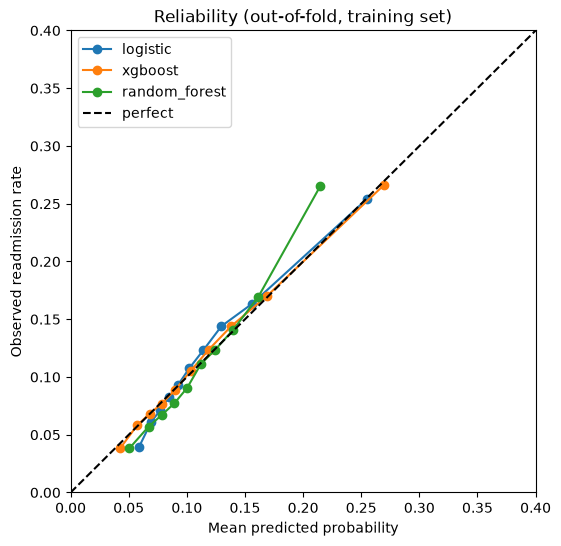

In [66]:
fig, ax = plt.subplots(figsize=(6, 6))
for name, p in oof.items():
    frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 0.4], [0, 0.4], "k--", label="perfect")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed readmission rate")
ax.set_xlim(0, 0.4); ax.set_ylim(0, 0.4)
ax.legend(); ax.set_title("Reliability (out-of-fold, training set)")
plt.show()

In [69]:
from sklearn.isotonic import IsotonicRegression

y_arr = y_train.to_numpy()
g_arr = groups_train.to_numpy()
cv_cal = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=11)

def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def calibrate_oof(p, method):
    out = np.zeros(len(p))
    for tr, te in cv_cal.split(p.reshape(-1, 1), y_arr, g_arr):
        if method == "sigmoid":
            m = LogisticRegression(penalty=None, max_iter=1000)
            m.fit(logit(p[tr]).reshape(-1, 1), y_arr[tr])
            out[te] = m.predict_proba(logit(p[te]).reshape(-1, 1))[:, 1]
        else:
            m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1)
            m.fit(p[tr], y_arr[tr])
            out[te] = m.predict(p[te])
    return out

for name, p in oof.items():
    variants = {"none": p,
                "sigmoid": calibrate_oof(p, "sigmoid"),
                "isotonic": calibrate_oof(p, "isotonic")}
    for label, q in variants.items():
        print(f"{name:14s} {label:9s} Brier {brier_score_loss(y_arr, q):.4f} | "
              f"slope {calib_slope(q, y_arr):.2f} | AUROC {roc_auc_score(y_arr, q):.4f}")

logistic       none      Brier 0.0974 | slope 1.03 | AUROC 0.6589
logistic       sigmoid   Brier 0.0974 | slope 1.00 | AUROC 0.6588
logistic       isotonic  Brier 0.0972 | slope 0.96 | AUROC 0.6569
xgboost        none      Brier 0.0962 | slope 1.01 | AUROC 0.6704
xgboost        sigmoid   Brier 0.0962 | slope 1.00 | AUROC 0.6704
xgboost        isotonic  Brier 0.0963 | slope 0.97 | AUROC 0.6689
random_forest  none      Brier 0.0969 | slope 1.37 | AUROC 0.6694
random_forest  sigmoid   Brier 0.0965 | slope 1.00 | AUROC 0.6694
random_forest  isotonic  Brier 0.0965 | slope 0.97 | AUROC 0.6683
